In [5]:
import pandas as pd
from google.colab import files
from IPython.display import display

# Upload dataset
uploaded = files.upload()

# Read CSV file
df = pd.read_csv("fraud_detection_50_records.csv")

# Display all 50 transactions
display(df)

# Display dataset information
print("Total records:", len(df))
print("Total columns:", len(df.columns))


Saving fraud_detection_50_records.csv to fraud_detection_50_records.csv


,Event_ID,Timestamp,Account_ID,Transaction_Type,Amount_MYR,Recipient_ID,Recipient_Country,Customer_Home_Country,Customer_Avg_Amount_MYR,Is_New_Recipient,...,High_Value_Transfers_Last_60min,Frequent_High_Value_Transfers,High_Value_Overseas_Transfer,Unusual_Transaction_Amount,New_Recipient_Transfer,Unusual_Device_or_Location,Triggered_Indicators,Risk_Score,Risk_Level,Synthetic_Rule_Label
0,FD-0001,2026-10-29 08:12:00,ACCT-1002,BANK_TRANSFER,5200.00,R-X1,MY,MY,1200,1,...,1,0,0,1,1,0,I3; I4,4,MEDIUM,1
1,FD-0002,2026-10-29 08:21:00,ACCT-1002,BANK_TRANSFER,6000.00,R-X1,MY,MY,1200,1,...,2,0,0,1,1,0,I3; I4,4,MEDIUM,1
2,FD-0003,2026-10-29 08:33:00,ACCT-1002,BANK_TRANSFER,5700.00,R-X1,MY,MY,1200,1,...,3,0,0,1,1,0,I3; I4,4,MEDIUM,1
3,FD-0004,2026-10-29 08:48:00,ACCT-1002,BANK_TRANSFER,8500.00,R-X1,MY,MY,1200,1,...,4,1,0,1,1,0,I1; I3; I4,7,HIGH,1
4,FD-0005,2026-10-29 08:55:00,ACCT-1002,BANK_TRANSFER,6400.00,R-X1,MY,MY,1200,1,...,5,1,0,1,1,0,I1; I3; I4,7,HIGH,1
5,FD-0006,2026-10-29 09:24:00,ACCT-1004,BANK_TRANSFER,5600.00,R-X2,MY,MY,1900,0,...,1,0,0,0,0,0,NaN,0,LOW,0
6,FD-0007,2026-10-29 09:32:00,ACCT-1004,BANK_TRANSFER,6300.00,R-X2,MY,MY,1900,0,...,2,0,0,1,0,0,I3,2,LOW,0
7,FD-0008,2026-10-29 09:48:00,ACCT-1004,BANK_TRANSFER,5100.00,R-X2,MY,MY,1900,0,...,3,0,0,0,0,0,NaN,0,LOW,0
8,FD-0009,2026-10-29 10:03:00,ACCT-1004,BANK_TRANSFER,7100.00,R-X2,MY,MY,1900,0,...,4,1,0,1,0,0,I1; I3,5,MEDIUM,1
9,FD-0010,2026-10-29 10:40:00,ACCT-1007,BANK_TRANSFER,12400.00,R-INT-ACCT-1007,SG,MY,2800,1,...,1,0,1,1,1,0,I2; I3; I4,7,HIGH,1


Total records: 50
Total columns: 24


Total Transactions: 50


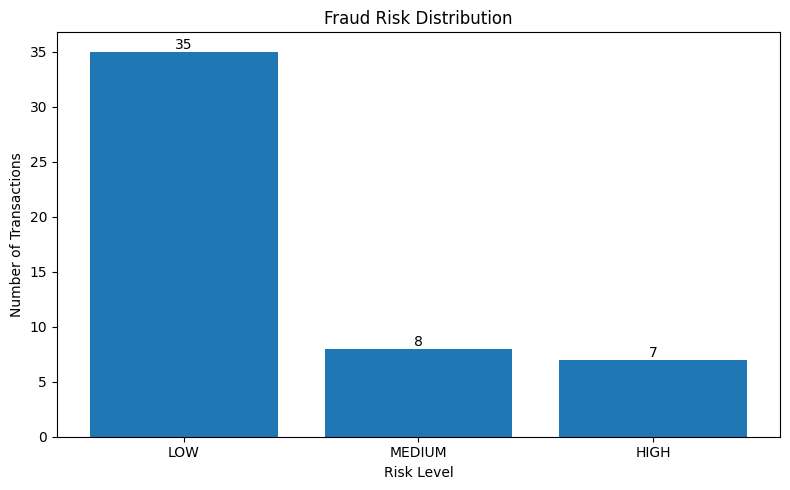

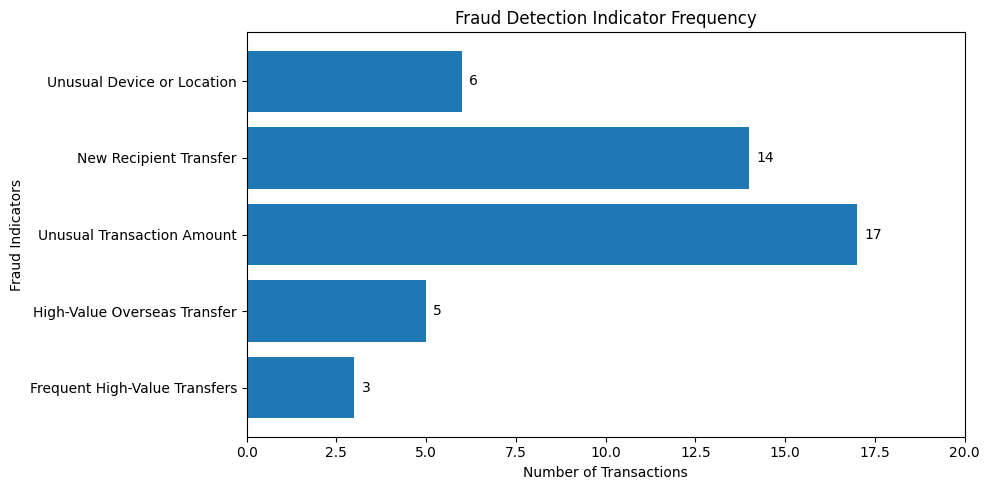

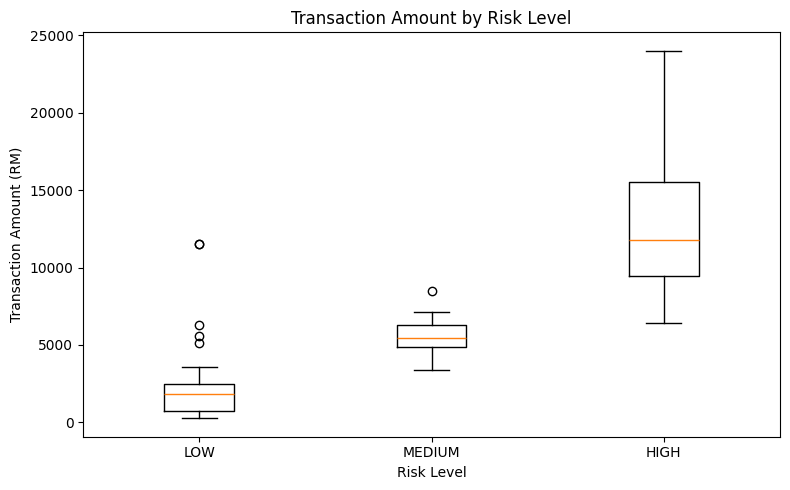

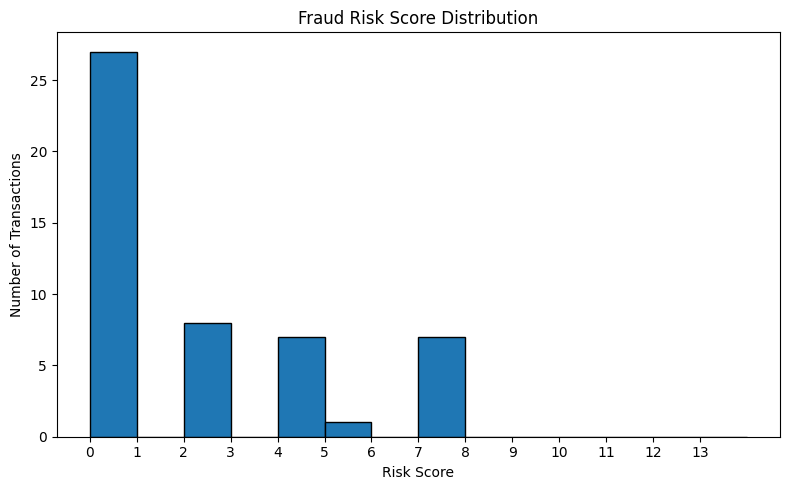

All four graphs generated successfully!


In [6]:

import pandas as pd
import matplotlib.pyplot as plt

# Use the existing DataFrame (df)
print("Total Transactions:", len(df))

# GRAPH 1: Fraud Risk Distribution
risk_counts = df["Risk_Level"].str.upper().value_counts()

risk_counts = risk_counts.reindex(
    ["LOW", "MEDIUM", "HIGH"], fill_value=0
)

plt.figure(figsize=(8, 5))
bars = plt.bar(risk_counts.index, risk_counts.values)

plt.title("Fraud Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Transactions")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        int(bar.get_height()),
        ha="center"
    )

plt.tight_layout()
plt.show()


# GRAPH 2: Fraud Detection Indicator Frequency
indicators = {
    "Frequent High-Value Transfers":
        "Frequent_High_Value_Transfers",

    "High-Value Overseas Transfer":
        "High_Value_Overseas_Transfer",

    "Unusual Transaction Amount":
        "Unusual_Transaction_Amount",

    "New Recipient Transfer":
        "New_Recipient_Transfer",

    "Unusual Device or Location":
        "Unusual_Device_or_Location"
}

counts = {}

for name, column in indicators.items():
    values = df[column].astype(str).str.lower()
    counts[name] = values.isin(
        ["1", "true", "yes"]
    ).sum()

plt.figure(figsize=(10, 5))
bars = plt.barh(list(counts.keys()), list(counts.values()))

plt.title("Fraud Detection Indicator Frequency")
plt.xlabel("Number of Transactions")
plt.ylabel("Fraud Indicators")

for bar in bars:
    plt.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        int(bar.get_width()),
        va="center"
    )

plt.xlim(0, max(counts.values()) + 3)
plt.tight_layout()
plt.show()


# GRAPH 3: Transaction Amount by Risk Level
df["Amount_MYR"] = pd.to_numeric(
    df["Amount_MYR"], errors="coerce"
)

data = [
    df.loc[
        df["Risk_Level"].str.upper() == level,
        "Amount_MYR"
    ].dropna()
    for level in ["LOW", "MEDIUM", "HIGH"]
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    data,
    tick_labels=["LOW", "MEDIUM", "HIGH"]
)

plt.title("Transaction Amount by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Transaction Amount (RM)")

plt.tight_layout()
plt.show()


# GRAPH 4: Fraud Risk Score Distribution
df["Risk_Score"] = pd.to_numeric(
    df["Risk_Score"], errors="coerce"
)

plt.figure(figsize=(8, 5))

plt.hist(
    df["Risk_Score"].dropna(),
    bins=range(0, 15),
    edgecolor="black"
)

plt.title("Fraud Risk Score Distribution")
plt.xlabel("Risk Score")
plt.ylabel("Number of Transactions")
plt.xticks(range(0, 14))

plt.tight_layout()
plt.show()

print("All four graphs generated successfully!")


Total Transactions: 50


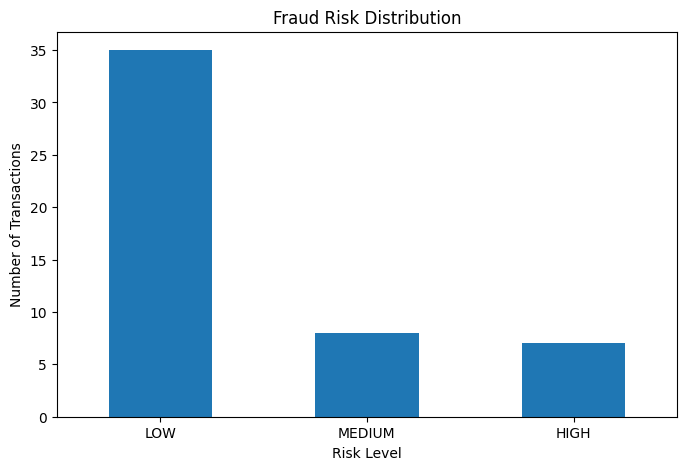

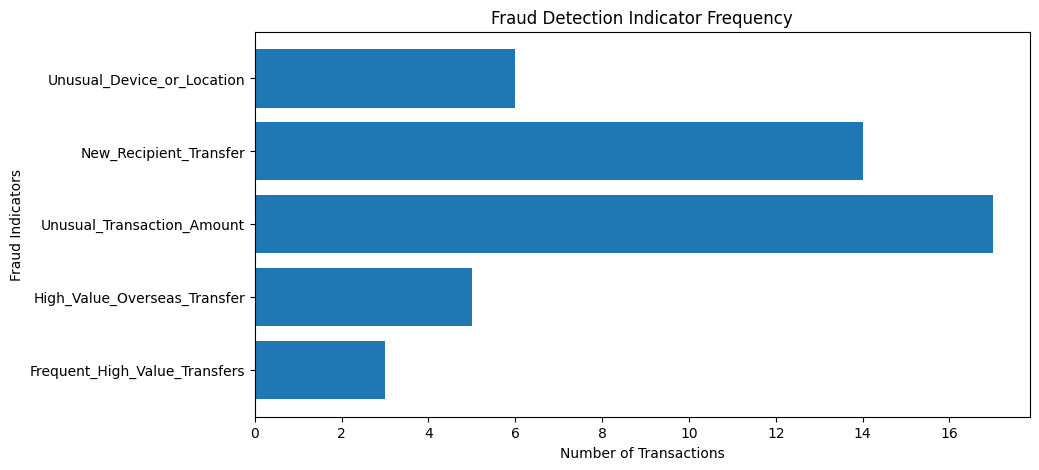

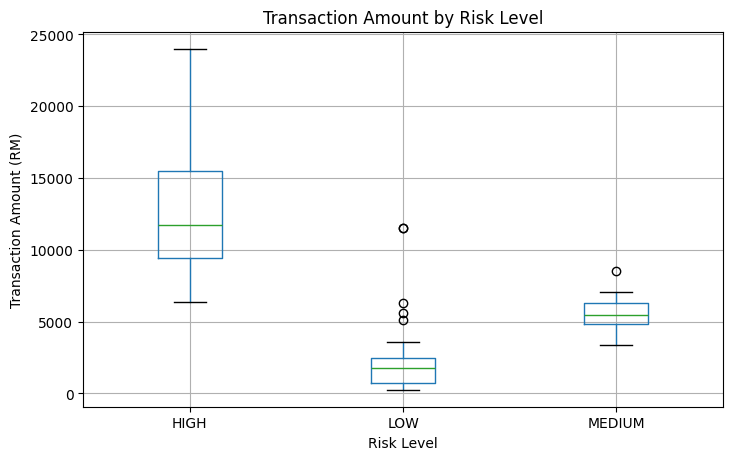

In [7]:

import pandas as pd
import matplotlib.pyplot as plt

# Use existing dataset (df)
print("Total Transactions:", len(df))


# GRAPH 1: Fraud Risk Distribution

risk = df["Risk_Level"].value_counts()

risk = risk.reindex(
    ["LOW", "MEDIUM", "HIGH"], fill_value=0
)

risk.plot(kind="bar", figsize=(8, 5))

plt.title("Fraud Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()


# GRAPH 2: Fraud Detection Indicator Frequency

# Five fraud indicators
indicators = [
    "Frequent_High_Value_Transfers",
    "High_Value_Overseas_Transfer",
    "Unusual_Transaction_Amount",
    "New_Recipient_Transfer",
    "Unusual_Device_or_Location"
]

# Count how many times each indicator occurs
counts = []

for indicator in indicators:
    count = df[indicator].isin(
        [True, 1, "True", "1"]
    ).sum()
    counts.append(count)

# Create horizontal bar graph
plt.figure(figsize=(10, 5))
plt.barh(indicators, counts)

plt.title("Fraud Detection Indicator Frequency")
plt.xlabel("Number of Transactions")
plt.ylabel("Fraud Indicators")
plt.show()


# GRAPH 3: Transaction Amount by Risk Level

df.boxplot(
    column="Amount_MYR",
    by="Risk_Level",
    figsize=(8, 5)
)

plt.title("Transaction Amount by Risk Level")
plt.suptitle("")
plt.xlabel("Risk Level")
plt.ylabel("Transaction Amount (RM)")
plt.show()


In [12]:

import pandas as pd
from IPython.display import display

# STEP 1: Use your existing dataset (df)

# Create a copy to keep the original data unchanged
fraud = df.copy()


# STEP 2: Link fraud indicators to MITRE F3

mitre = {
    "Frequent_High_Value_Transfers":
        ("F1047", "Transfer of Funds"),

    "High_Value_Overseas_Transfer":
        ("F1025", "Electronic Funds Transfer"),

    "Unusual_Transaction_Amount":
        ("F1047", "Transfer of Funds"),

    "New_Recipient_Transfer":
        ("F1047", "Transfer of Funds"),

    "Unusual_Device_or_Location":
        ("F1006", "Account Takeover")
}


# STEP 3: Check each transaction

results = []

for index, row in fraud.iterrows():

    for indicator, technique in mitre.items():

        # Check whether the indicator was triggered
        if str(row[indicator]).lower() in ["true", "1", "yes"]:

            # Store the mapping result
            results.append({
                "Transaction ID": row["Event_ID"],
                "Fraud Indicator": indicator.replace("_", " "),
                "MITRE ID": technique[0],
                "MITRE Technique": technique[1],
                "Risk Level": row["Risk_Level"],
                "MITRE Link":
                    "https://ctid.mitre.org/fightfraud/#/technique/"
                    + technique[0]
            })


# STEP 4: Convert results into a table

mitre_df = pd.DataFrame(results)

print("MITRE F3 Fraud Mapping Results")

display(mitre_df)


# STEP 5: Save the results

mitre_df.to_csv("mitre_fraud_mapping.csv", index=False)

print("Mapping completed successfully!")


MITRE F3 Fraud Mapping Results


,Transaction ID,Fraud Indicator,MITRE ID,MITRE Technique,Risk Level,MITRE Link
0,FD-0001,Unusual Transaction Amount,F1047,Transfer of Funds,MEDIUM,https://ctid.mitre.org/fightfraud/#/technique/...
1,FD-0001,New Recipient Transfer,F1047,Transfer of Funds,MEDIUM,https://ctid.mitre.org/fightfraud/#/technique/...
2,FD-0002,Unusual Transaction Amount,F1047,Transfer of Funds,MEDIUM,https://ctid.mitre.org/fightfraud/#/technique/...
3,FD-0002,New Recipient Transfer,F1047,Transfer of Funds,MEDIUM,https://ctid.mitre.org/fightfraud/#/technique/...
4,FD-0003,Unusual Transaction Amount,F1047,Transfer of Funds,MEDIUM,https://ctid.mitre.org/fightfraud/#/technique/...
5,FD-0003,New Recipient Transfer,F1047,Transfer of Funds,MEDIUM,https://ctid.mitre.org/fightfraud/#/technique/...
6,FD-0004,Frequent High Value Transfers,F1047,Transfer of Funds,HIGH,https://ctid.mitre.org/fightfraud/#/technique/...
7,FD-0004,Unusual Transaction Amount,F1047,Transfer of Funds,HIGH,https://ctid.mitre.org/fightfraud/#/technique/...
8,FD-0004,New Recipient Transfer,F1047,Transfer of Funds,HIGH,https://ctid.mitre.org/fightfraud/#/technique/...
9,FD-0005,Frequent High Value Transfers,F1047,Transfer of Funds,HIGH,https://ctid.mitre.org/fightfraud/#/technique/...


Mapping completed successfully!
